In [1]:
#Rotulagem de componentes conectados (Connected Component Labeling)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from skimage.measure import label
from scipy.spatial import cKDTree
from skimage.morphology import remove_small_objects
from skimage.color import label2rgb, gray2rgb
from skimage.measure import label, regionprops
from skimage.morphology import skeletonize
from skimage.util import invert
from skan import Skeleton, summarize
from itertools import combinations
from scipy.ndimage import distance_transform_edt
from skimage.segmentation import watershed

In [16]:
def podar_esqueleto_por_orientacao(esqueleto_img, angulo_limite_graus=45):
    """
    Poda ramos em junções de um esqueleto. A lógica é preservar o par de
    ramos mais colinear (mais próximo de 180°) e remover os demais.

    Args:
        esqueleto_img (np.ndarray): A imagem binária do esqueleto.
        angulo_limite_graus (int): O desvio máximo em graus em relação a uma
                                   linha reta (180°) para considerar dois
                                   ramos como uma continuação. Se a melhor
                                   combinação de ramos tiver uma diferença
                                   maior que este limite, nada é podado.

    Returns:
        np.ndarray: A imagem do esqueleto podado.
    """
    # 1. Analisar o esqueleto usando a biblioteca 'skan'
    esqueleto_obj = Skeleton(esqueleto_img)
    summary = summarize(esqueleto_obj)

    # Se skan não encontrar ramos, retorna a imagem original
    if summary.shape[0] == 0:
        print("Nenhum ramo encontrado no esqueleto.")
        return np.copy(esqueleto_img)

    esqueleto_podado = np.copy(esqueleto_img)
    
    # 2. Encontrar pontos de junção (nós com grau >= 3)
    pontos_de_juncao_ids = np.where(esqueleto_obj.degrees >= 3)[0]

    print(f"Encontrados {len(pontos_de_juncao_ids)} pontos de junção para análise.")

    # 3. Analisar cada junção
    for junction_id in pontos_de_juncao_ids:
        # Pega as coordenadas da junção atual
        j_coords = esqueleto_obj.coordinates[junction_id]
        
        # Encontra todos os ramos (arestas) que se conectam a esta junção
        ramos_conectados = summary[(summary['node-id-src'] == junction_id) | (summary['node-id-dst'] == junction_id)]
        
        # Pula se, por algum motivo, não for uma junção válida (menos de 3 ramos)
        if len(ramos_conectados) < 3:
            continue

        # Calcula o ângulo de cada ramo que sai da junção
        ramos_info = []
        for _, ramo in ramos_conectados.iterrows():
            # Precisamos do ID do outro nó para formar o vetor do ramo
            other_node_id = ramo['node-id-dst'] if ramo['node-id-src'] == junction_id else ramo['node-id-src']
            other_coords = esqueleto_obj.coordinates[int(other_node_id)]

            # Calcula o vetor (dy, dx) do centro da junção para a ponta do ramo
            dy = other_coords[0] - j_coords[0]
            dx = other_coords[1] - j_coords[1]
            
            # Calcula o ângulo e o ID do ramo (skeleton-id)
            angle = np.degrees(np.arctan2(-dy, dx)) # -dy para alinhar com o sistema de coordenadas de imagem
            ramos_info.append({'id': ramo.name, 'angle': angle})

        # 4. Encontrar o par de ramos mais colinear
        melhor_par = None
        menor_diff_de_180 = 180.0

        # Testa todas as combinações de 2 ramos
        for r1, r2 in combinations(ramos_info, 2):
            # Calcula a diferença absoluta de ângulo
            diff = abs(r1['angle'] - r2['angle'])
            
            # Queremos a diferença em relação a 180 graus
            diff_de_180 = abs(diff - 180)
            
            # Corrige o caso em que o ângulo passa de 360 (e.g., -170 e 170)
            if diff_de_180 > 180:
                diff_de_180 = 360 - diff_de_180

            # Se esta for a combinação mais próxima de 180° até agora, salva
            if diff_de_180 < menor_diff_de_180:
                menor_diff_de_180 = diff_de_180
                # Armazena os IDs dos ramos do melhor par
                melhor_par = {r1['id'], r2['id']}

        # 5. Aplicar a poda se um par adequado for encontrado
        # O par deve ser colinear o suficiente (abaixo do nosso 'angulo_limite_graus')
        if melhor_par and menor_diff_de_180 < angulo_limite_graus:
            # Itera por todos os ramos da junção novamente
            for ramo in ramos_info:
                if ramo['id'] not in melhor_par:
                    print(f"  -> Podando ramo {ramo['id']} (desalinhado) na junção {junction_id}.")
                    # Obtém as coordenadas de todos os pixels do ramo a ser podado
                    path_coords = esqueleto_obj.path_coordinates(int(ramo['id']))
                    # Define o valor desses pixels para 0, removendo-os da imagem
                    if len(path_coords) > 1:
                        esqueleto_podado[path_coords[1, 0], path_coords[1, 1]] = 0
        #else:
            #print(f"  -> Nenhum par suficientemente colinear na junção {junction_id}. Nada podado.")

    return esqueleto_podado

def label_binary_img(binary_img, connectivity=2, remove_small_obj=False, min_size=100):
    """
    Rotula uma imagem binária, atribuindo rótulos únicos a componentes conectados.

    Args:
        binary_img (np.ndarray): Imagem binária (True/False ou 1/0).
        connectivity (int): Conectividade a ser usada (1 ou 2).

    Returns:
        np.ndarray: Imagem rotulada onde cada componente conectado tem um rótulo único.
    """
    
    esqueleto_img = skeletonize(binary_img)

    skeleton_obj = Skeleton(esqueleto_img)

    degrees = skeleton_obj.degrees
    indices_juncoes = np.where(degrees >= 3)[0]

    coords_juncoes = skeleton_obj.coordinates[indices_juncoes].astype(int)
    esqueleto_colorido = gray2rgb((esqueleto_img * 255).astype(np.uint8))
    esqueleto_podado = np.copy(esqueleto_img)

    print(f"Encontrados {len(coords_juncoes)} pontos de junção. Colorindo de vermelho e removendo...")

    offset = 1

    for y, x in coords_juncoes:
        y_min = max(0, y - offset)
        y_max = min(esqueleto_colorido.shape[0], y + offset + 1)
        x_min = max(0, x - offset)
        x_max = min(esqueleto_colorido.shape[1], x + offset + 1)
        esqueleto_colorido[y_min:y_max, x_min:x_max] = (255, 0, 0)

        # Remove todos os pixels conectados ao ponto de junção
        esqueleto_podado[y, x+1] = False
        esqueleto_podado[y, x-1] = False
    
    esqueleto_rotulado = label(esqueleto_podado, connectivity=connectivity)

    if remove_small_obj:
        esqueleto_rotulado = remove_small_objects(esqueleto_rotulado, min_size=min_size)

    coords_esqueleto = np.argwhere(esqueleto_rotulado > 0)
    labels_esqueleto = esqueleto_rotulado[coords_esqueleto[:, 0], coords_esqueleto[:, 1]]
    coords_forma = np.argwhere(binary_img)

    kdtree = cKDTree(coords_esqueleto)
    _, indices_vizinhos = kdtree.query(coords_forma)

    labels_mapeados = labels_esqueleto[indices_vizinhos]

    binary_rotulada = np.zeros_like(binary_img, dtype=np.uint8)
    binary_rotulada[coords_forma[:, 0], coords_forma[:, 1]] = labels_mapeados

    return esqueleto_colorido, esqueleto_rotulado, esqueleto_podado, binary_rotulada

def separar_fibras(binary_img, angulo_limite_poda=45, remover_pequenos_esqueletos=True, tam_min_esqueleto=100):
    """
    Pipeline completo para esqueletizar, podar junções e rotular fibras.

    Args:
        binary_img (np.ndarray): Imagem binária original das fibras.
        angulo_limite_poda (int): Desvio máximo de 180° para considerar um par de ramos como contínuo.
        remover_pequenos_esqueletos (bool): Se True, remove pequenos fragmentos de esqueleto após a poda.
        tam_min_esqueleto (int): Tamanho mínimo do esqueleto para ser mantido.

    Returns:
        np.ndarray: Imagem final com cada fibra separada e rotulada.
        np.ndarray: Imagem dos esqueletos rotulados e podados.
    """
    print("1. Esqueletizando a imagem binária...")
    esqueleto_img = skeletonize(binary_img)

    print("2. Podando junções com base na colinearidade dos ramos...")
    esqueleto_podado = podar_esqueleto_por_orientacao(esqueleto_img, angulo_limite_graus=angulo_limite_poda)

    print("3. Rotulando os segmentos de esqueleto desconectados...")
    esqueleto_rotulado = label(esqueleto_podado, connectivity=2) # connectivity=2 é geralmente melhor

    if remover_pequenos_esqueletos:
        print(f"4. Removendo fragmentos de esqueleto menores que {tam_min_esqueleto} pixels...")
        esqueleto_rotulado = remove_small_objects(esqueleto_rotulado, min_size=tam_min_esqueleto)

    # (A próxima etapa responde à sua Questão 2)
    print("5. Propagando rótulos dos esqueletos para as fibras usando Watershed...")
    
    # Calcula o mapa de distância da imagem binária original
    # A distância será maior no centro das fibras
    distancia = distance_transform_edt(binary_img)

    # O algoritmo watershed "inunda" a imagem a partir de marcadores.
    # Nossos marcadores são os esqueletos rotulados.
    # A topografia é o negativo da distância (inundamos dos picos para os vales).
    # A máscara garante que os rótulos fiquem contidos apenas dentro das fibras originais.
    fibras_rotuladas = watershed(-distancia, markers=esqueleto_rotulado, mask=binary_img)
    
    return fibras_rotuladas, esqueleto_rotulado

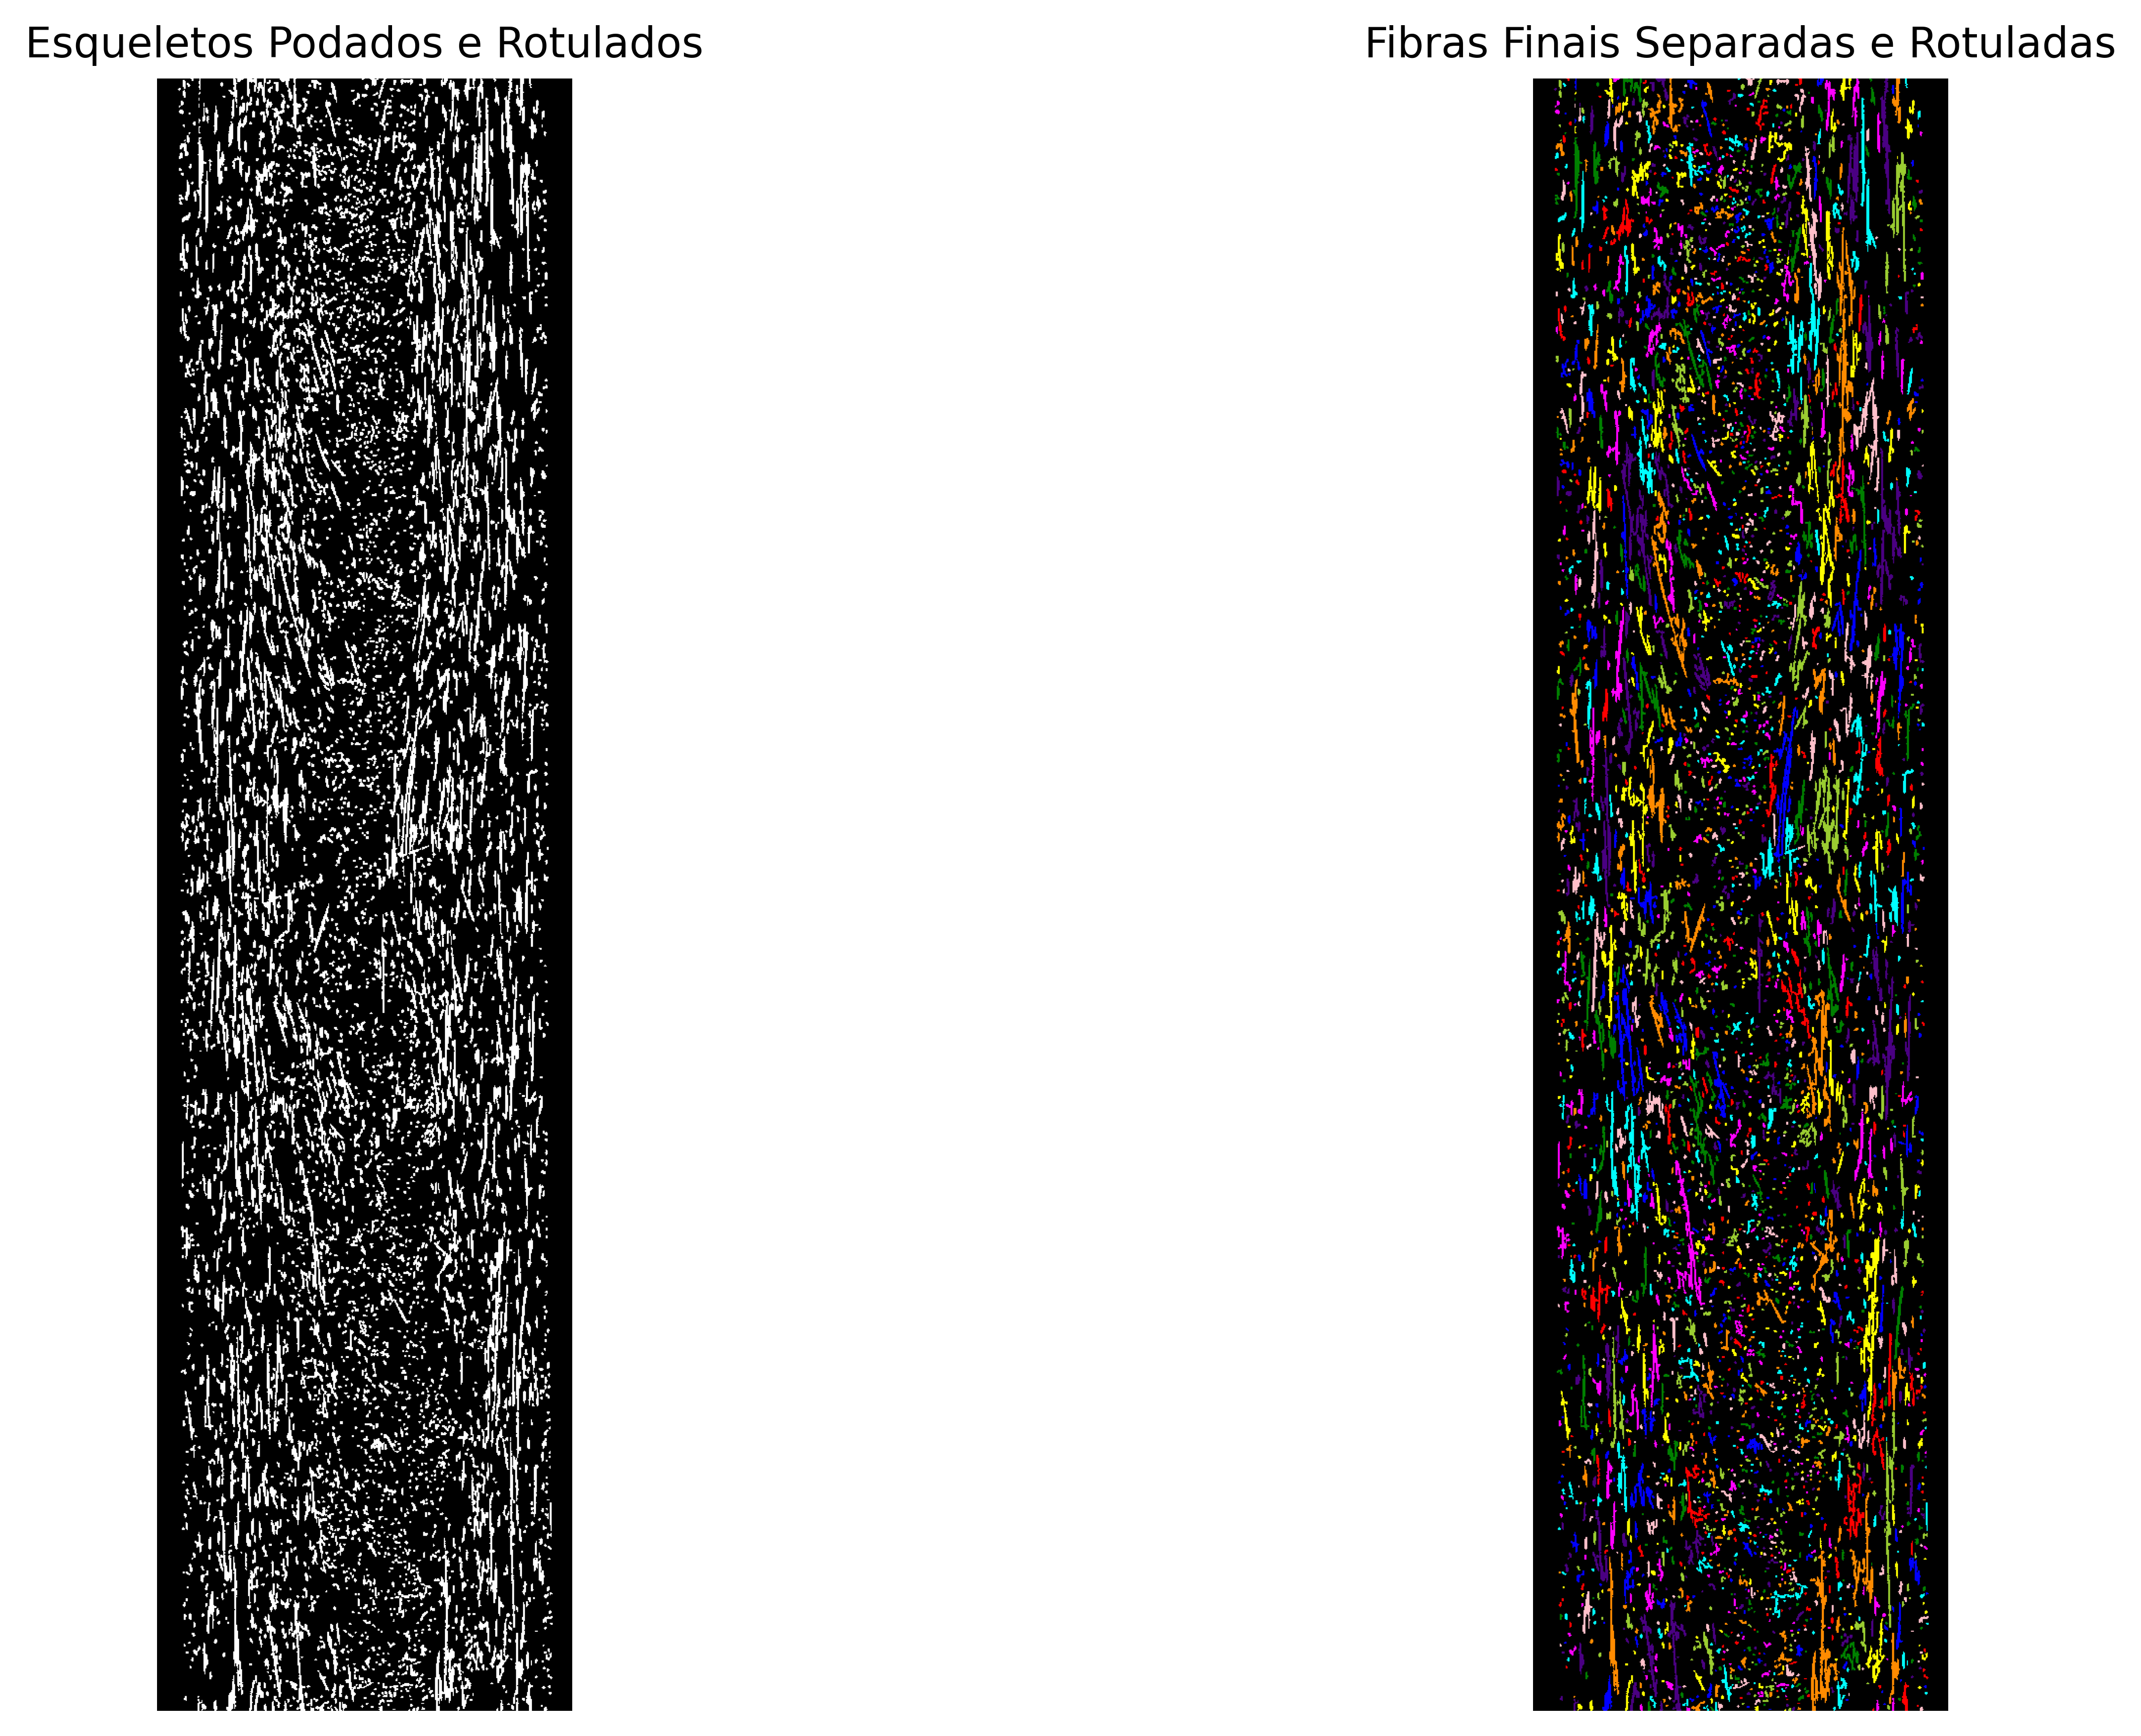

In [6]:
img = Image.open("./fiber_img/slice_400.tiff").convert("L")
imagem = np.array(img)
binaria = imagem > 200
binaria_limpa = remove_small_objects(binaria, min_size=50)

rotulada = label(binaria_limpa, connectivity=2)

plt.figure(figsize=(15, 7), dpi=500)

plt.subplot(1, 2, 1)
plt.imshow(binaria_limpa, cmap='gray')
plt.title("Esqueletos Podados e Rotulados")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(label2rgb(rotulada, bg_label=0), cmap='gray')
plt.title("Fibras Finais Separadas e Rotuladas")
plt.axis('off')

plt.tight_layout()
plt.show()

Encontrados 5046 pontos de junção. Colorindo de vermelho e removendo...


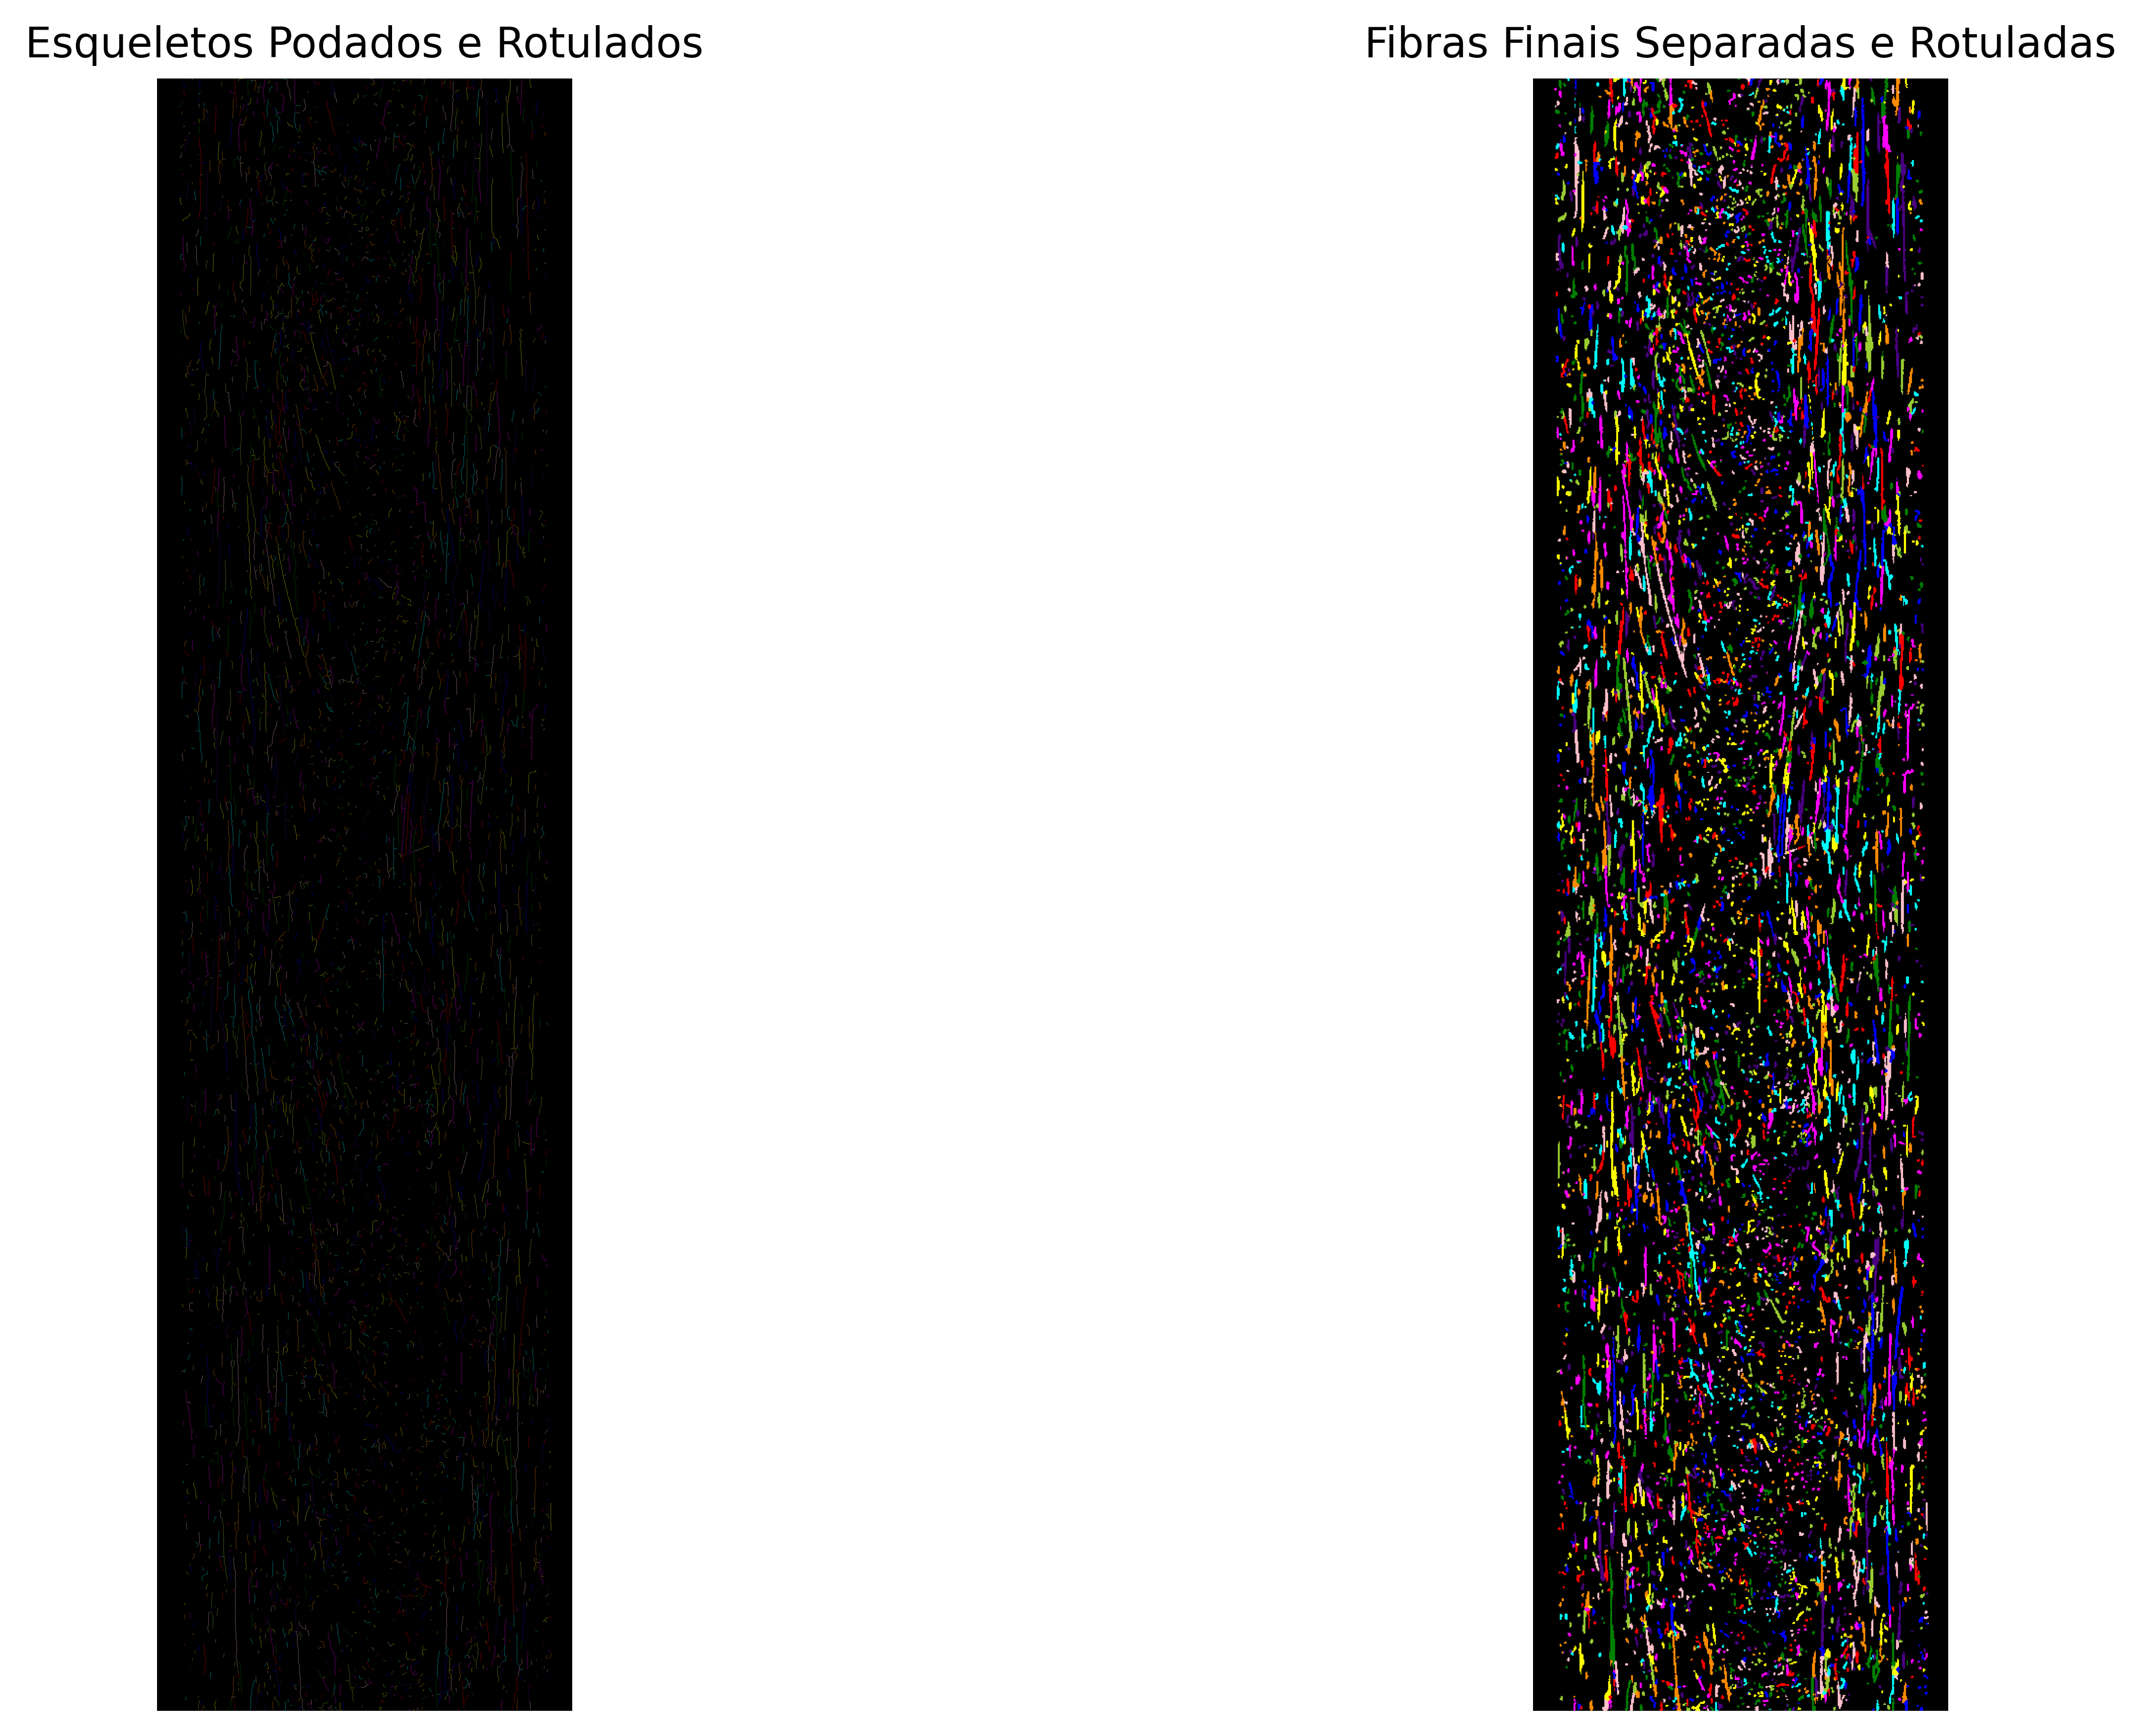

In [4]:
esqueleto_colorido, esqueleto_rotulado, esqueleto_sem_juncoes, binary_rotulada = label_binary_img(
    binaria_limpa, connectivity=2, remove_small_obj=True, min_size=10)

# Visualização dos resultados
plt.figure(figsize=(15, 7), dpi=500)

plt.subplot(1, 2, 1)
plt.imshow(label2rgb(esqueleto_rotulado, bg_label=0), cmap='gray')
plt.title("Esqueletos Podados e Rotulados")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(label2rgb(binary_rotulada, bg_label=0), cmap='gray')
plt.title("Fibras Finais Separadas e Rotuladas")
plt.axis('off')

plt.tight_layout()
plt.show()

1. Esqueletizando a imagem binária...
2. Podando junções com base na colinearidade dos ramos...


/tmp/ipykernel_9534/556100392.py:19: VisibleDeprecationWarning: separator in column name will change to _ in version 0.13; to silence this warning, use `separator='-'` to maintain current behavior and use `separator='_'` to switch to the new default behavior.
  summary = summarize(esqueleto_obj)


Encontrados 5046 pontos de junção para análise.
  -> Podando ramo 18 (desalinhado) na junção 133.
  -> Podando ramo 20 (desalinhado) na junção 152.
  -> Podando ramo 26 (desalinhado) na junção 221.
  -> Podando ramo 31 (desalinhado) na junção 310.
  -> Podando ramo 37 (desalinhado) na junção 373.
  -> Podando ramo 40 (desalinhado) na junção 387.
  -> Podando ramo 42 (desalinhado) na junção 401.
  -> Podando ramo 50 (desalinhado) na junção 518.
  -> Podando ramo 52 (desalinhado) na junção 522.
  -> Podando ramo 54 (desalinhado) na junção 600.
  -> Podando ramo 56 (desalinhado) na junção 614.
  -> Podando ramo 60 (desalinhado) na junção 663.
  -> Podando ramo 62 (desalinhado) na junção 683.
  -> Podando ramo 65 (desalinhado) na junção 816.
  -> Podando ramo 21 (desalinhado) na junção 842.
  -> Podando ramo 70 (desalinhado) na junção 894.
  -> Podando ramo 74 (desalinhado) na junção 996.
  -> Podando ramo 73 (desalinhado) na junção 1021.
  -> Podando ramo 79 (desalinhado) na junção 1083.


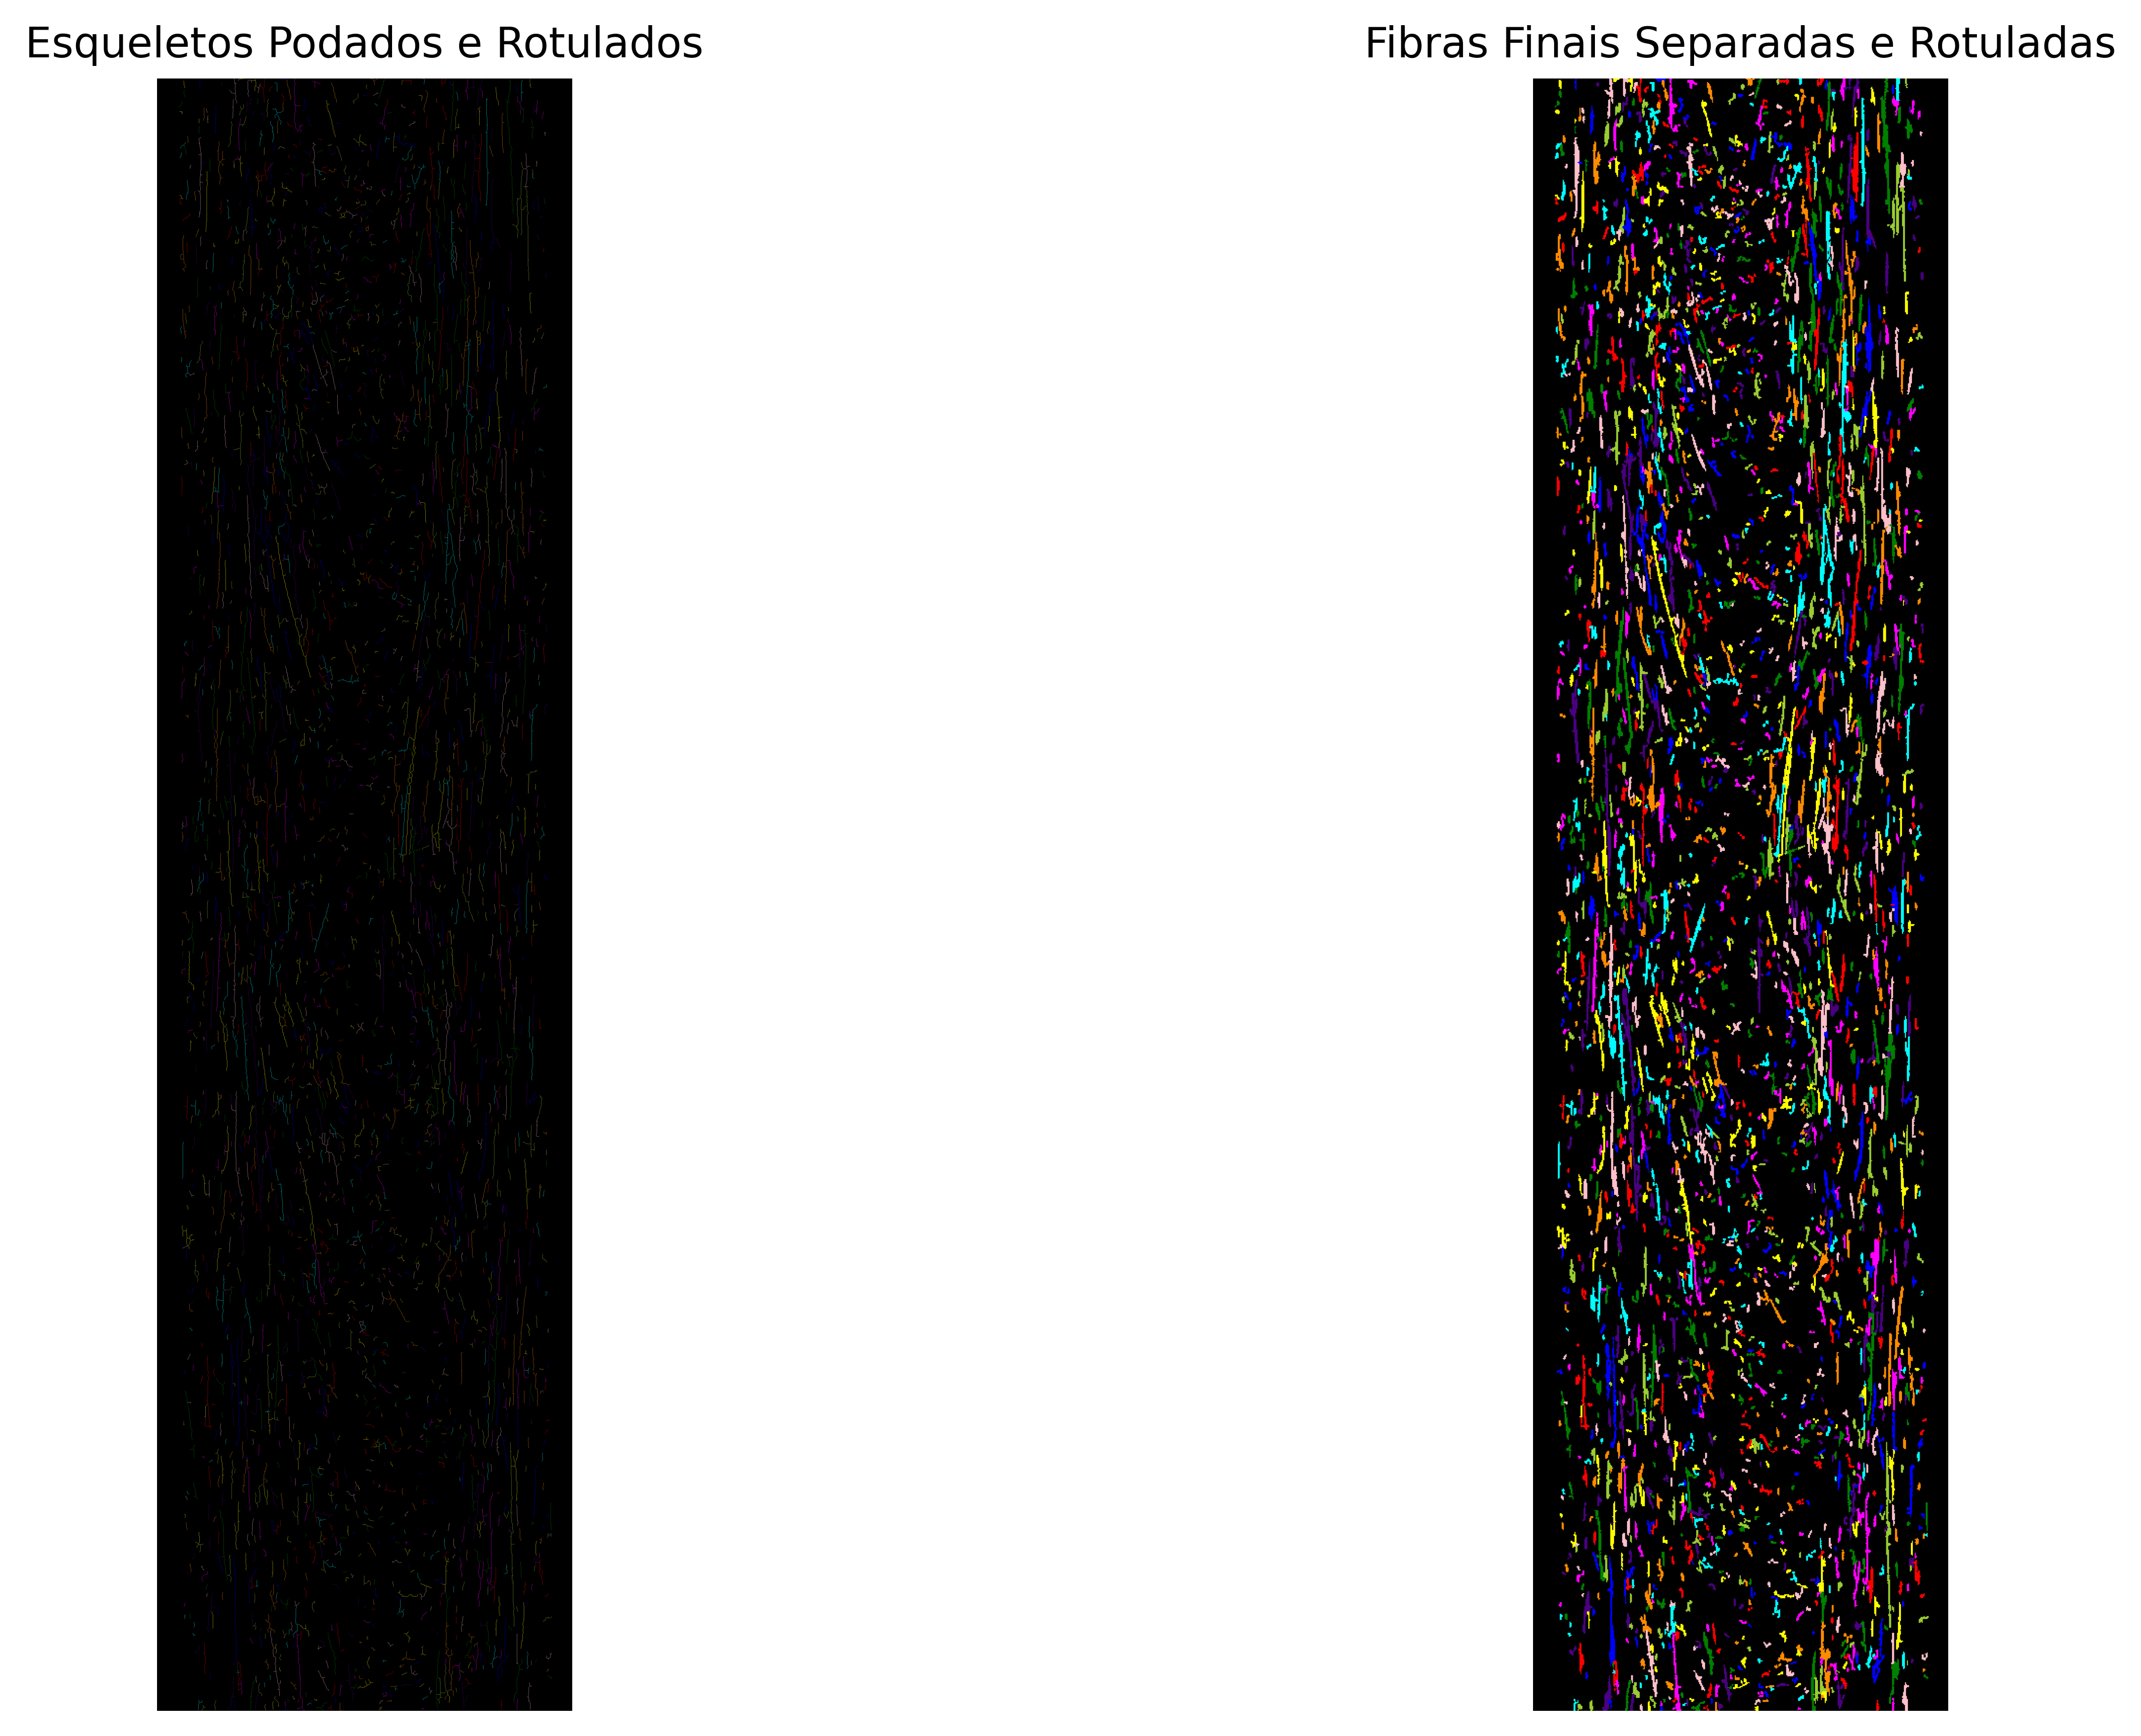

In [23]:
# Carregue sua imagem como antes
img = Image.open("./fiber_img/slice_400.tiff").convert("L")
imagem = np.array(img)
binaria = imagem > 200
binaria_limpa = remove_small_objects(binaria, min_size=50)

# Execute o novo pipeline
# Ajuste o 'angulo_limite_poda' e 'tam_min_esqueleto' conforme necessário
fibras_separadas, esqueletos_separados = separar_fibras(
    binaria_limpa, 
    angulo_limite_poda=45,
    remover_pequenos_esqueletos=True, 
    tam_min_esqueleto=20
)

# Visualização dos resultados
plt.figure(figsize=(15, 7), dpi=500)

plt.subplot(1, 2, 1)
plt.imshow(label2rgb(esqueletos_separados, bg_label=0), cmap='gray')
plt.title("Esqueletos Podados e Rotulados")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(label2rgb(fibras_separadas, bg_label=0), cmap='gray')
plt.title("Fibras Finais Separadas e Rotuladas")
plt.axis('off')

plt.tight_layout()
plt.show()